# Duopoly Simulation Analysis
This notebook builds upon the initial data loading script and provides a comprehensive suite of tools and visualizations to test and evaluate the performance of your current duopoly simulation.

## 1. Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

# Styling settings for plots
%matplotlib inline
plt.style.use('ggplot')
sns.set_context('notebook')
pd.options.mode.chained_assignment = None

## 2. Load Simulation Data
Load the `duopoly_feedback.data` pickle file.

In [2]:
with open('duopoly_feedback.data', 'rb') as handle:
    feedback = pickle.load(handle)

print("Data loaded successfully!")
print("Available Keys:", list(feedback.keys()))

Data loaded successfully!
Available Keys: ['history', 'current_simulation', 'cumulative_revenue_current_selling_season']


C:\Users\creep\AppData\Local\Temp\ipykernel_33628\3339520292.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  feedback = pickle.load(handle)


## 3. Top-Level Summary
Quickly check the overall revenue and simulation ID before diving into the detailed history.

In [3]:
sim_id = feedback.get('current_simulation', 'Unknown')
final_rev = feedback.get('cumulative_revenue_current_selling_season', 0.0)

print(f"Simulation ID: {sim_id}")
print(f"Total Cumulative Revenue: ${final_rev:,.2f}")

Simulation ID: f0a08126-b469-493c-b9f0-9975c880851a
Total Cumulative Revenue: $786.40


## 4. History Data Overview
Extract the history dataframe and check basic descriptive statistics to understand price and demand ranges.

In [4]:
history_df = feedback['history']
display(history_df.head())
display(history_df.describe())

,simulation,day,season,demand,own_price,competitor_price,remaining_capacity,revenue,cumulative_revenue
0,ef945f67-f564-418e-931c-0789bd589d63,1.0,1.0,0.0,41.837023,27.396698,80.0,0.000000,0.000000
1,ef945f67-f564-418e-931c-0789bd589d63,2.0,1.0,0.0,41.837023,41.837023,80.0,0.000000,0.000000
2,ef945f67-f564-418e-931c-0789bd589d63,3.0,1.0,0.0,41.837023,41.837023,80.0,0.000000,0.000000
3,ef945f67-f564-418e-931c-0789bd589d63,4.0,1.0,1.0,41.837023,41.837023,79.0,41.837023,41.837023
4,ef945f67-f564-418e-931c-0789bd589d63,5.0,1.0,0.0,41.837023,41.837023,79.0,0.000000,41.837023


,day,season,demand,own_price,competitor_price,remaining_capacity,revenue,cumulative_revenue
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,50.500000,50.500000,0.780400,27.659596,28.045637,45.973525,17.407122,885.250617
std,28.866431,28.866431,0.958175,19.593946,19.866835,24.152028,26.960625,745.217747
min,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,25.750000,25.750000,0.000000,12.318688,12.484423,26.000000,0.000000,312.303003
50%,50.500000,50.500000,1.000000,23.563340,23.819710,50.000000,1.768899,688.463929
75%,75.250000,75.250000,1.000000,39.357983,39.814757,67.000000,26.953680,1269.708632
max,100.000000,100.000000,7.000000,120.000000,120.000000,80.000000,275.141836,4376.275214


## 5. Visualizing Pricing Strategies
Compare your pricing strategy (`own_price`) against the `competitor_price` over the course of the season. A 7-day rolling average is used to improve readability and smooth out daily fluctuations.

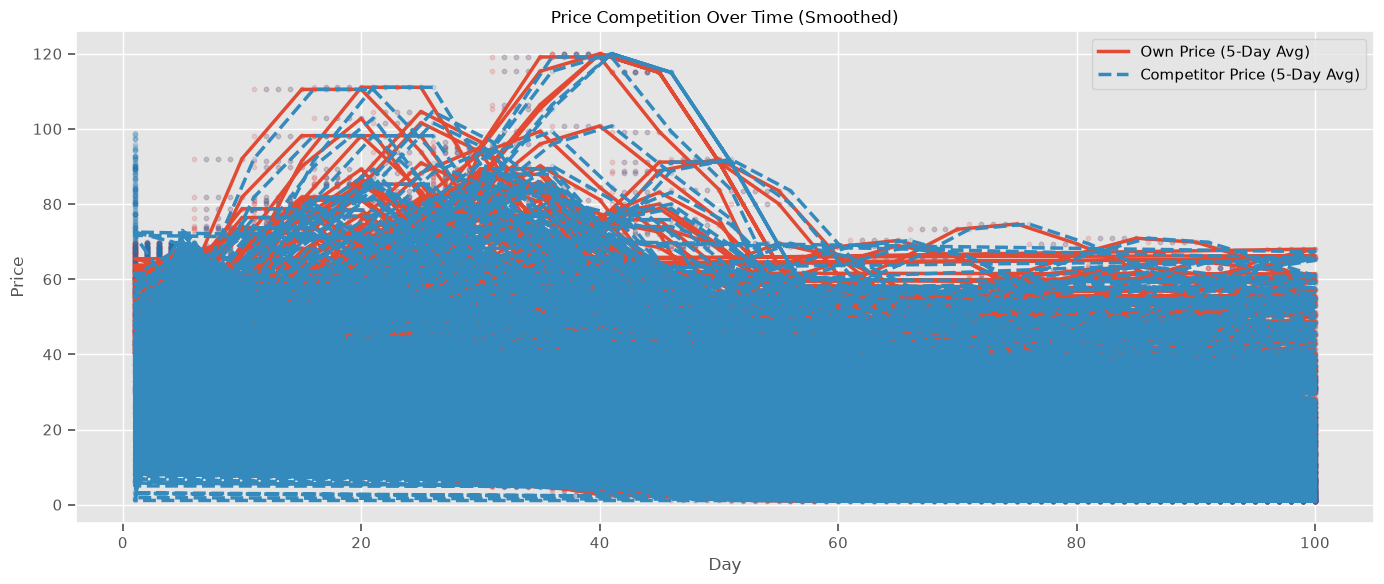

In [7]:
plt.figure(figsize=(14, 6))
# Calculate a rolling window for smoother curves
window_size = 5
own_price_smooth = history_df['own_price'].rolling(window=window_size, min_periods=1).mean()
comp_price_smooth = history_df['competitor_price'].rolling(window=window_size, min_periods=1).mean()

# Plot the smoothed averages
plt.plot(history_df['day'], own_price_smooth, label=f'Own Price ({window_size}-Day Avg)', linewidth=2.5)
plt.plot(history_df['day'], comp_price_smooth, label=f'Competitor Price ({window_size}-Day Avg)', linewidth=2.5, linestyle='--')

# Overlay the raw data as faint dots in the background
plt.scatter(history_df['day'], history_df['own_price'], alpha=0.15, s=10, color='tab:red')
plt.scatter(history_df['day'], history_df['competitor_price'], alpha=0.15, s=10, color='tab:blue')

plt.title('Price Competition Over Time (Smoothed)')
plt.xlabel('Day')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Demand & Capacity Analysis
Observe how demand occurs over time and how it depletes your remaining capacity.

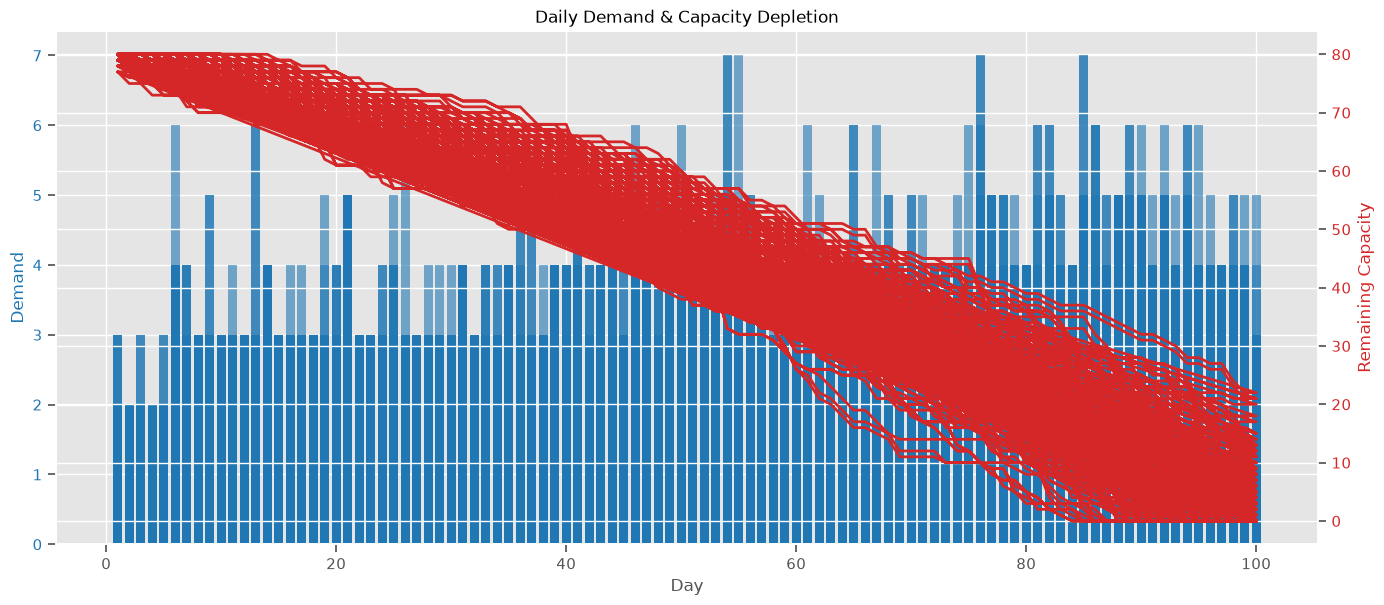

In [8]:
fig, ax1 = plt.subplots(figsize=(14, 6))

color = 'tab:blue'
ax1.set_xlabel('Day')
ax1.set_ylabel('Demand', color=color)
ax1.bar(history_df['day'], history_df['demand'], color=color, alpha=0.6, label='Demand')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Remaining Capacity', color=color)
ax2.plot(history_df['day'], history_df['remaining_capacity'], color=color, linewidth=2, label='Capacity')
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  
plt.title('Daily Demand & Capacity Depletion')
plt.show()

## 7. Revenue Tracking
Visualize cumulative revenue growth over the selling season.

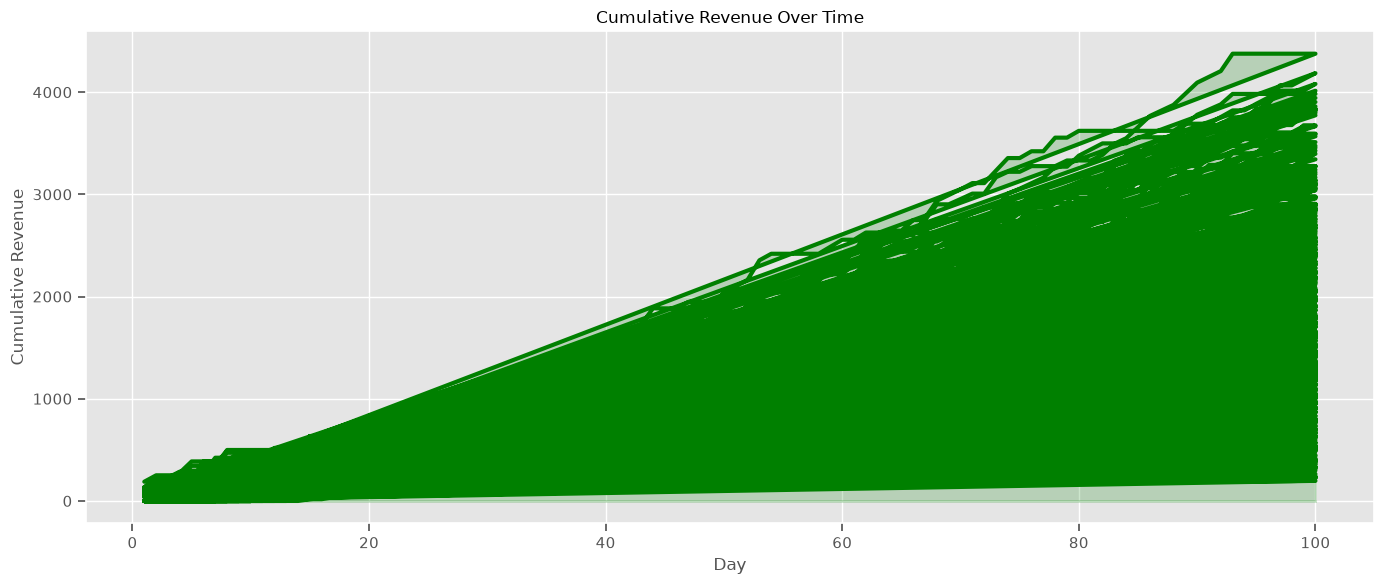

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(history_df['day'], history_df['cumulative_revenue'], color='green', linewidth=3)
plt.fill_between(history_df['day'], history_df['cumulative_revenue'], color='green', alpha=0.2)
plt.title('Cumulative Revenue Over Time')
plt.xlabel('Day')
plt.ylabel('Cumulative Revenue')
plt.tight_layout()
plt.show()

## 8. Competitor vs. Own Price Distribution
Look at the distribution of prices to see if you are generally pricing higher or lower than the competitor.

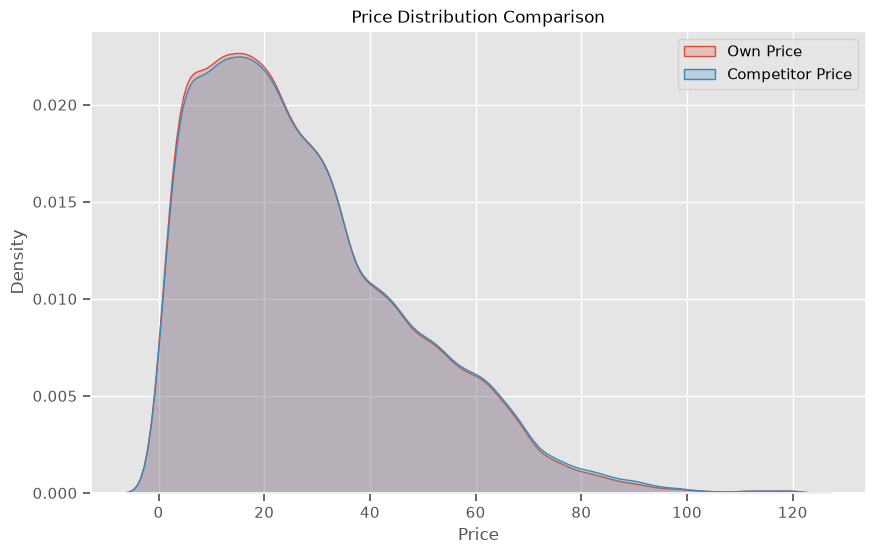

In [10]:
plt.figure(figsize=(10, 6))
sns.kdeplot(history_df['own_price'], label='Own Price', fill=True)
sns.kdeplot(history_df['competitor_price'], label='Competitor Price', fill=True)
plt.title('Price Distribution Comparison')
plt.xlabel('Price')
plt.legend()
plt.show()